In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

## Mendel and Pea Flowers ##

In [5]:
predicted_proportions = make_array(.75, .25)
sample_proportions(929, predicted_proportions)

array([ 0.75349839,  0.24650161])

In [6]:
def purple_flowers():
    return sample_proportions(929, predicted_proportions).item(0) * 100

In [9]:
purple_flowers()

76.21097954790098

In [10]:
purples = make_array()

for i in np.arange(10000):
    new_purple = purple_flowers()
    purples = np.append(purples, new_purple)

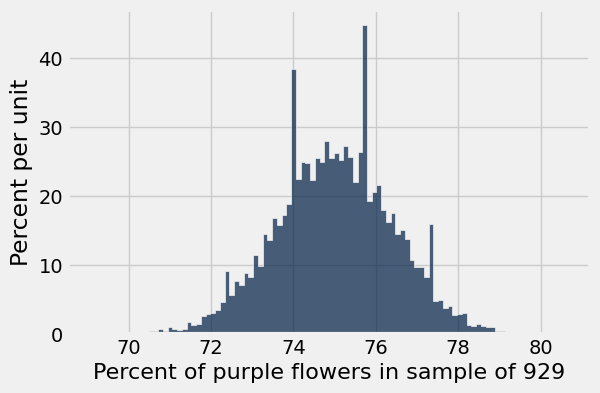

In [11]:
Table().with_column('Percent of purple flowers in sample of 929', purples).hist(bins=100)

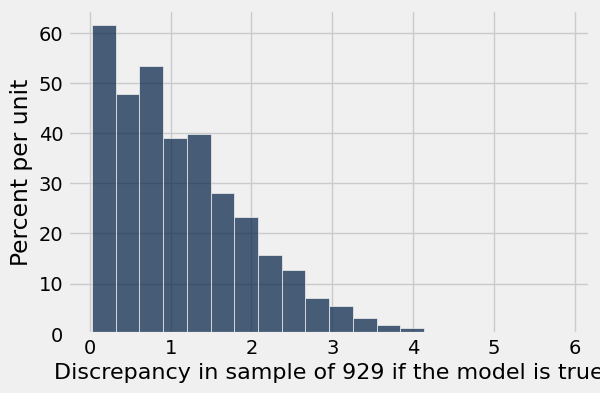

In [12]:
Table().with_column('Discrepancy in sample of 929 if the model is true', abs(purples- 75)).hist(bins=20)

In [13]:
## Mendel had 929 plants, of which 709 had purple flowers
observed_purples = 709 / 929
observed_purples

0.7631862217438106

In [14]:
diff = abs(observed_purples * 100 - 75)
diff

1.318622174381062

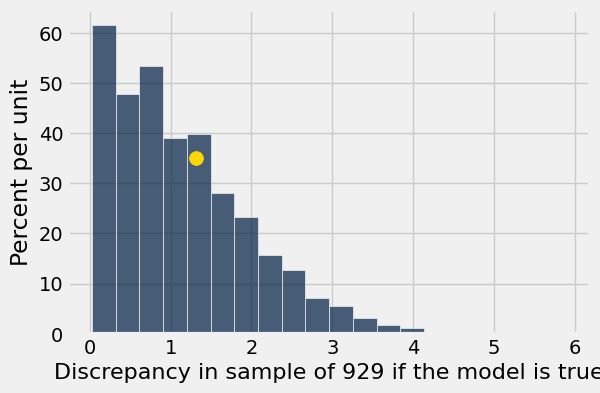

In [15]:
Table().with_column('Discrepancy in sample of 929 if the model is true', abs(purples- 75)).hist(bins=20)
plots.scatter(diff, .35, c='gold', s=100)

In [17]:
simulated_data = Table().with_column('Discrepancy in sample of 929 if the model is true', abs(purples- 75))
simulated_data

Discrepancy in sample of 929 if the model is true
0.83423
0.995694
0.242196
1.53391
1.21098
0.565124
0.296017
0.296017
0.40366
2.7718


In [24]:
test_statistic = 100*abs(709/929 - .75)
test_statistic

# How many simulated outcomes are more extreme than test statistic?
simulated_data.where('Discrepancy in sample of 929 if the model is true', are.above_or_equal_to(test_statistic)).num_rows / simulated_data.num_rows

0.367

## Why not just look at P(709 purple)?

In [ ]:
predicted_proportions = make_array(.75, .25)

def purple_count():
    return round(sample_proportions(929, predicted_proportions).item(0) * 929)

# Run the experiment
repetitions = 100000
purple_counts = make_array()

for _ in np.arange(repetitions):
    new_count = purple_count()
    purple_counts = np.append(purple_counts, new_count)

# Store in a table
purple_table = Table().with_columns('Count of purple', purple_counts)
purple_table

In [ ]:
# How often did we get 709?
ratio = purple_table.where('Count of purple', 709).num_rows / purple_table.num_rows
print('Percent of outcomes with exactly 709 purple: ', ratio)

In [ ]:
# Plot this!
purple_table.hist('Count of purple', bins=np.arange(650, 750, 1))
plots.scatter(x=709, y=ratio, color='gold', s=100)
plots.title('P(709 purple): ' + str(ratio))